## Key Findings

1. **Severe class imbalance.** 3.5% of transactions are fraud. A model that predicts
   "not fraud" for everything would score 96.5% accuracy while catching no fraud, so
   I evaluate with AUC-PR and recall at fixed precision instead.

2. **Fraud rate changes over time.** The daily fraud rate swings between ~1% and ~7%,
   with the first ~25 days noticeably lower. The first 80% and last 20% of the data
   have similar overall rates (3.51% vs 3.44%), so the drift shows up day to day rather
   than in long averages. I use a time-based split (train on earlier, validate on later)
   to match how the model would be used in production and to avoid leaking future data.

3. **Heavy missingness.** 168 of 394 columns are more than 70% empty.

4. **Missingness is informative, not random.** Rows with the fewest missing values have
   8.0% fraud vs ~1.6-2.9% for the rest. I keep NaNs as-is (XGBoost handles them)
   rather than filling them with averages, which would erase this signal.

5. **Product type explains most of the identity effect.** Transactions with identity
   info have 7.85% fraud vs 2.09% without. But product W (74% of data, ~2% fraud)
   never has identity info, while other products almost always do, so these
   patterns largely describe the same split.

6. **Identity still adds signal within a product.** Within product C, rows with
   identity have 12.3% fraud vs 5.8% without (small group of ~6.3k rows;
   association, not causation).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
tx = pd.read_parquet("src/data/processed/train_transaction.parquet")
print(tx.shape, f"| {tx.memory_usage(deep=True).sum() / 1e6:.0f} MB in memory")

(590540, 394) | 978 MB in memory


Days covered: 1 to 182


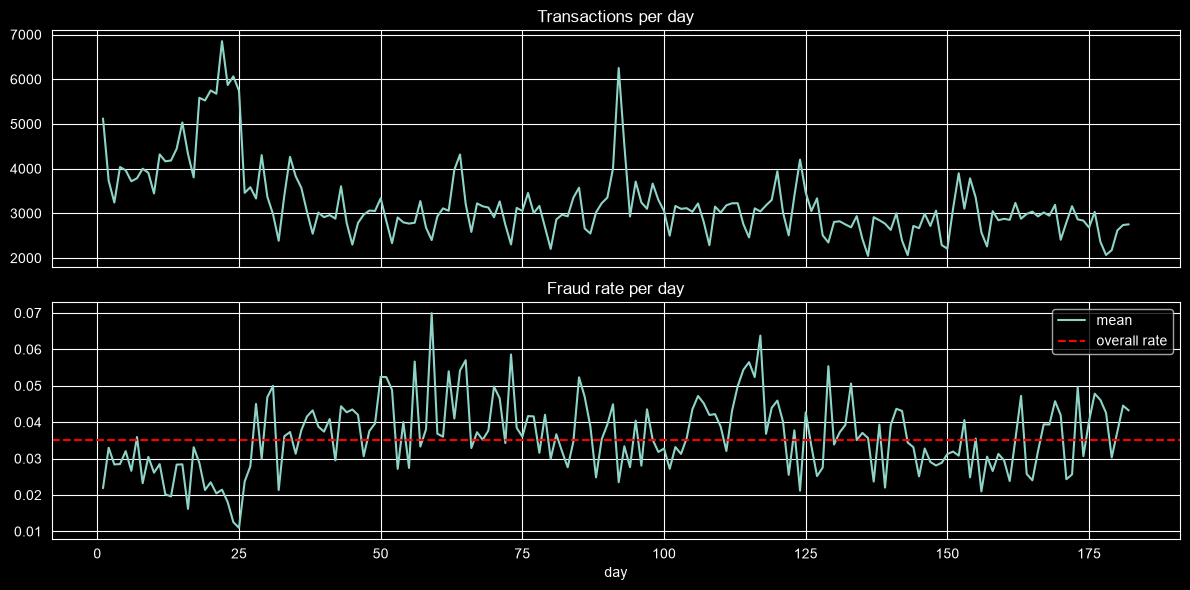

In [3]:
tx["day"] = tx["TransactionDT"] // 86400
print("Days covered:", tx["day"].min(), "to", tx["day"].max())

daily = tx.groupby("day")["isFraud"].agg(["count", "mean"])

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
daily["count"].plot(ax=axes[0], title="Transactions per day")
daily["mean"].plot(ax=axes[1], title="Fraud rate per day")
axes[1].axhline(tx["isFraud"].mean(), color="red", linestyle="--", label="overall rate")
axes[1].legend()
plt.tight_layout()
plt.show()

In [4]:
cut = tx["TransactionDT"].quantile(0.8)
early = tx[tx["TransactionDT"] <= cut]
late = tx[tx["TransactionDT"] > cut]

print(f"Fraud rate, first 80%: {early['isFraud'].mean():.4f}  ({len(early):,} rows)")
print(f"Fraud rate, last 20%:  {late['isFraud'].mean():.4f}  ({len(late):,} rows)")

Fraud rate, first 80%: 0.0351  (472,432 rows)
Fraud rate, last 20%:  0.0344  (118,108 rows)


In [5]:
missing = tx.isna().mean().sort_values(ascending=False)
print("Columns more than 70% missing:", (missing > 0.7).sum(), "of", len(missing))
missing.head(15)

Columns more than 70% missing: 168 of 395


dist2    0.936284
D7       0.934099
D13      0.895093
D14      0.894695
D12      0.890410
D6       0.876068
D9       0.873123
D8       0.873123
V153     0.861237
V149     0.861237
V141     0.861237
V146     0.861237
V154     0.861237
V162     0.861237
V142     0.861237
dtype: float64

In [6]:
idn_ids = pd.read_parquet("src/data/processed/train_identity.parquet",
                          columns=["TransactionID"])
tx["has_identity"] = tx["TransactionID"].isin(idn_ids["TransactionID"]).astype("int8")

print(tx.groupby("has_identity")["isFraud"].agg(["count", "mean"]))

               count      mean
has_identity                  
0             446307  0.020939
1             144233  0.078470


In [ ]:
feature_cols = tx.columns.drop(["isFraud", "day", "has_identity"])
tx["n_missing"] = tx[feature_cols].isna().sum(axis=1)

tx["n_missing_bin"] = pd.qcut(tx["n_missing"], 5, duplicates="drop")
print(tx.groupby("n_missing_bin", observed=True)["isFraud"].agg(["count", "mean"]))

In [ ]:
# Fraud rate by product type
print(tx.groupby("ProductCD")["isFraud"].agg(["count", "mean"]))

# What share of each product type has identity info?
print(pd.crosstab(tx["ProductCD"], tx["has_identity"], normalize="index").round(3))

# Do the low-missing rows mostly have identity info?
print(tx.groupby("n_missing_bin", observed=True)["has_identity"].mean().round(3))

In [ ]:
c = tx[tx["ProductCD"] == "C"]
print(c.groupby("has_identity")["isFraud"].agg(["count", "mean"]))